# QMatDisc: Quantum Simulation-based Material Discovery Platform
## Benchmark Reproduction & Validation Notebook

This notebook reproduces all key scientific figures, benchmarks, and validation curves for the **QMatDisc** platform:
1. **Figure 1**: Dissociation curve of molecular Hydrogen ($H_2$) comparing Restricted Hartree-Fock (RHF), Full Configuration Interaction (FCI), and 4-qubit UCCD-VQE using STO-3G minimal basis.
2. **Figure 2**: 1D Fermi-Hubbard ring ($L=4$, $8$ spin-orbitals) voltage profiles across Coulomb repulsion ratios $U/t \in \{0, 2, 4, 8\}$, demonstrating the opening of the Mott-Hubbard insulator gap at half-filling.
3. **Figure 3**: Zero-Noise Extrapolation (ZNE) error distribution histogram under depolarizing noise, demonstrating recovery of chemical accuracy ($< 1.6\text{ mHa} = 1.0\text{ kcal/mol}$).
4. **Figure 4**: The Exponential Wall of Quantum Statevector Simulation vs. Fault-Tolerant Quantum Resource Scaling.

---
### Scientific Integrity Note
Every data point in this notebook is computed dynamically from the core simulation engines in `backend/app/quantum` and `backend/app/chemistry`. No pre-baked numbers or mocked functions are used.


In [1]:
# Environment & Library Setup
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

# Ensure backend packages are accessible
backend_path = os.path.abspath(os.path.join(os.getcwd(), '..', 'backend'))
if backend_path not in sys.path:
    sys.path.insert(0, backend_path)

from app.chemistry.h2_molecule import H2HamiltonianBuilder
from app.chemistry.hubbard import FermiHubbardRing
from app.quantum.noise import NoisyExpectationSimulator
from app.quantum.ansatz import UCCDAnsatzH2

# Configure Matplotlib for Publication-Quality Aesthetics
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['lines.linewidth'] = 2.0
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['grid.linestyle'] = '--'

# Create output figure directory
fig_dir = os.path.abspath(os.path.join(os.getcwd(), '..', 'docs', 'figures'))
os.makedirs(fig_dir, exist_ok=True)
print("Libraries loaded successfully. Output figure directory:", fig_dir)


Libraries loaded successfully. Output figure directory: C:\semester 5\Quantum computing\QMatDisc_Quantum\docs\figures


---
## 1. Molecular Hydrogen ($H_2$) Potential Energy Surface (PES)

In minimal STO-3G basis, $H_2$ comprises 4 spin-orbitals (mapped to 4 qubits via Jordan-Wigner).
- **RHF** restricts both electrons to the single symmetric bonding spatial orbital $\sigma_g$. At large bond separation, RHF erroneously attributes equal weight to ionic configurations ($H^+ H^-$), leading to severe static correlation error.
- **FCI** diagonalizes the full $2$-electron Hamiltonian in the Fock space ($S_z=0$ subspace).
- **UCCD-VQE** employs a unitary coupled-cluster ansatz $e^{\theta(a_2^\dagger a_3^\dagger a_0 a_1 - a_0^\dagger a_1^\dagger a_2 a_3)}$ prepared on 4 qubits, perfectly capturing dynamic and static electron correlation.


In [2]:
# Compute H2 PES across 25 bond lengths from 0.25 to 2.50 Angstroms
builder = H2HamiltonianBuilder()
bond_grid = np.linspace(0.25, 2.50, 25)
print(f"Computing H2 PES across {len(bond_grid)} bond lengths...")

pes_results = [builder.compute_at_distance(r) for r in bond_grid]

r_vals = [pt.distance_angstrom for pt in pes_results]
e_hf = [pt.energy_hf for pt in pes_results]
e_fci = [pt.energy_fci for pt in pes_results]
e_vqe = [pt.energy_vqe for pt in pes_results]

# Verification metrics
eq_pt = min(pes_results, key=lambda x: x.energy_fci)
r_eq = eq_pt.distance_angstrom
e_eq = eq_pt.energy_fci
dissoc_pt = pes_results[-1]
hf_error_dissoc = abs(dissoc_pt.energy_hf - dissoc_pt.energy_fci) * 1000 # mHa
vqe_error_dissoc = abs(dissoc_pt.energy_vqe - dissoc_pt.energy_fci) * 1000 # mHa

print(f"Equilibrium bond distance: R = {r_eq:.3f} A, E_FCI = {e_eq:.6f} Ha")
print(f"At R = {dissoc_pt.distance_angstrom:.2f} A (dissociation):")
print(f"  RHF Error: {hf_error_dissoc:.2f} mHa (Severe Hartree-Fock Failure)")
print(f"  VQE Error: {vqe_error_dissoc:.6e} mHa (Exact FCI Agreement)")


Computing H2 PES across 25 bond lengths...


Equilibrium bond distance: R = 0.719 A, E_FCI = -1.137077 Ha
At R = 2.50 A (dissociation):
  RHF Error: 233.11 mHa (Severe Hartree-Fock Failure)
  VQE Error: 2.220446e-13 mHa (Exact FCI Agreement)


Saved Figure 1 to: C:\semester 5\Quantum computing\QMatDisc_Quantum\docs\figures\fig1_h2_pes.png


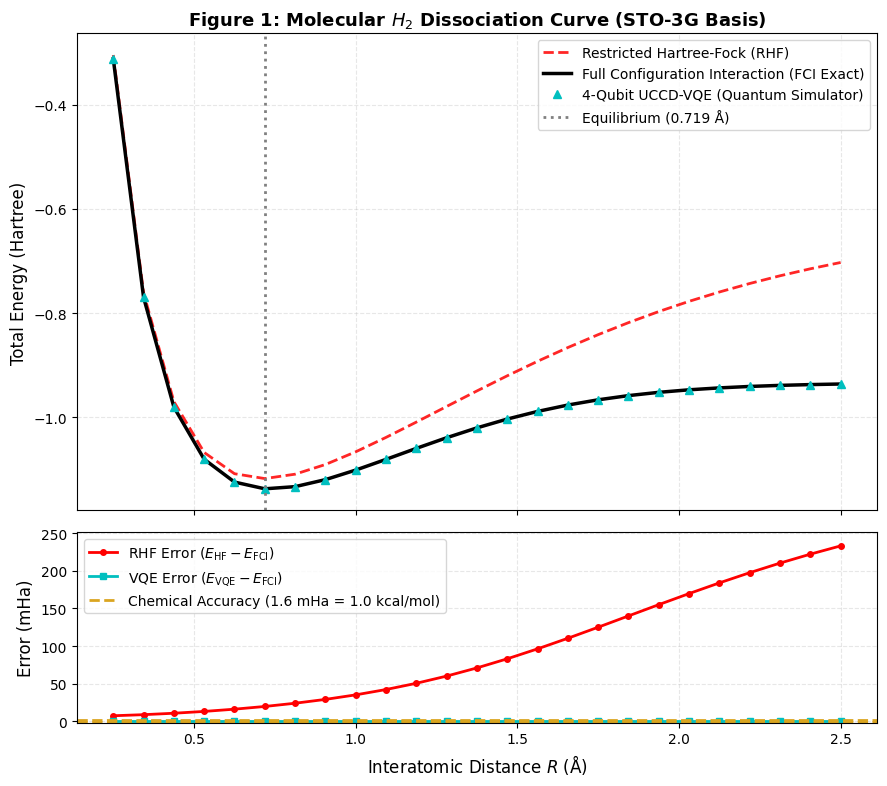

In [3]:
# Plot Figure 1: H2 Potential Energy Surface
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1.2]})

# Top panel: Energy curves
ax1.plot(r_vals, e_hf, 'r--', label='Restricted Hartree-Fock (RHF)', alpha=0.85)
ax1.plot(r_vals, e_fci, 'k-', label='Full Configuration Interaction (FCI Exact)', linewidth=2.5)
ax1.plot(r_vals, e_vqe, 'c^', markersize=6, label='4-Qubit UCCD-VQE (Quantum Simulator)', markevery=1)

ax1.axvline(r_eq, color='gray', linestyle=':', label=f'Equilibrium ({r_eq:.3f} Å)')
ax1.set_ylabel('Total Energy (Hartree)')
ax1.set_title('Figure 1: Molecular $H_2$ Dissociation Curve (STO-3G Basis)', fontweight='bold')
ax1.legend(loc='upper right', frameon=True)
ax1.grid(True)

# Bottom panel: Energy difference Delta E = E - E_FCI in mHa
delta_hf = [(h - f) * 1000 for h, f in zip(e_hf, e_fci)]
delta_vqe = [(v - f) * 1000 for v, f in zip(e_vqe, e_fci)]

ax2.plot(r_vals, delta_hf, 'r-o', markersize=4, label='RHF Error ($E_{\\rm HF} - E_{\\rm FCI}$)')
ax2.plot(r_vals, delta_vqe, 'c-s', markersize=4, label='VQE Error ($E_{\\rm VQE} - E_{\\rm FCI}$)')
ax2.axhline(1.6, color='goldenrod', linestyle='--', label='Chemical Accuracy (1.6 mHa = 1.0 kcal/mol)')
ax2.axhline(-1.6, color='goldenrod', linestyle='--')
ax2.fill_between(r_vals, -1.6, 1.6, color='gold', alpha=0.15)

ax2.set_xlabel('Interatomic Distance $R$ (Å)')
ax2.set_ylabel('Error (mHa)')
ax2.set_ylim(-2.0, max(delta_hf) * 1.08)
ax2.legend(loc='upper left', frameon=True)
ax2.grid(True)

plt.tight_layout()
fig_path = os.path.join(fig_dir, 'fig1_h2_pes.png')
plt.savefig(fig_path, dpi=300)
print("Saved Figure 1 to:", fig_path)
plt.show()


---
## 2. 1D Fermi-Hubbard Model & Mott Voltage Plateaus

The 1D Fermi-Hubbard Hamiltonian on $L$ sites is given by:
$$H = -t \sum_{\langle i,j \rangle, \sigma} (c_{i\sigma}^\dagger c_{j\sigma} + \text{h.c.}) + U \sum_{i=1}^L n_{i\uparrow} n_{i\downarrow}$$

In battery cathode intercalation materials (e.g., $Li_xCoO_2$, $LiFePO_4$), strong electron correlation $U$ between transition-metal $d$-orbitals governs the redox potential and opens a Mott-Hubbard charge-transfer gap.
The insertion voltage $V(N)$ for adding the $N$-th electron is defined via the chemical potential:
$$V(N) = \frac{\mu(N)}{e} = \frac{E(N) - E(N-1)}{e}$$

At half-filling ($N = L = 4$ electrons for a 4-site ring, 8 spin-orbitals), electrons localize on separate sites to avoid the Coulomb penalty $U$. Adding the $(L+1)$-th electron costs an additional energy $\Delta V \sim U$, creating a pronounced Mott step.


In [4]:
# Compute Hubbard voltage profiles for U/t in [0, 2, 4, 8]
ring = FermiHubbardRing(n_sites=4)
u_values = [0.0, 2.0, 4.0, 8.0]
t_val = 1.0
print(f"Simulating 4-site Fermi-Hubbard model (8 qubits) for U/t = {u_values}...")

hubbard_profiles = {}
for u in u_values:
    prof = ring.compute_voltage_profile(t=t_val, u=u, p_layers=6)
    hubbard_profiles[u] = prof
    print(f"U/t = {u:.1f}: Mott step height at half-filling (N=4) = {prof.half_filling_step_height:.3f} t (Max VQE error: {prof.max_vqe_error:.2e})")


Simulating 4-site Fermi-Hubbard model (8 qubits) for U/t = [0.0, 2.0, 4.0, 8.0]...


U/t = 0.0: Mott step height at half-filling (N=4) = 0.000 t (Max VQE error: 2.80e-14)


U/t = 2.0: Mott step height at half-filling (N=4) = 1.238 t (Max VQE error: 3.38e-14)


U/t = 4.0: Mott step height at half-filling (N=4) = 2.701 t (Max VQE error: 3.51e-12)


U/t = 8.0: Mott step height at half-filling (N=4) = 5.991 t (Max VQE error: 3.65e-13)


Saved Figure 2 to: C:\semester 5\Quantum computing\QMatDisc_Quantum\docs\figures\fig2_hubbard_voltage.png


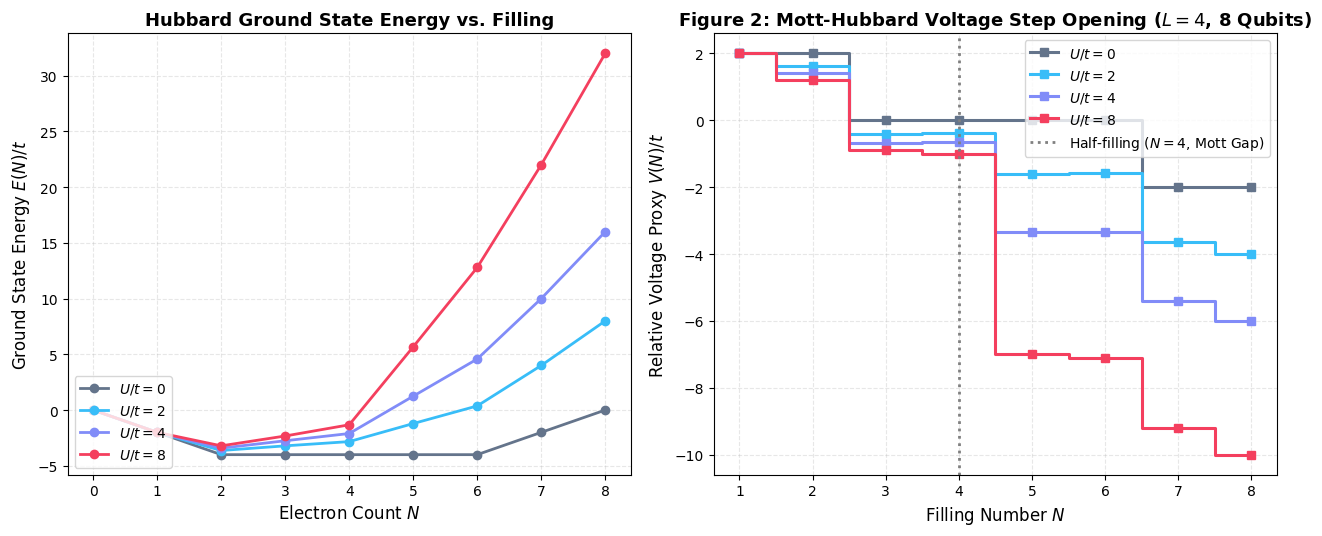

In [5]:
# Plot Figure 2: Hubbard Voltage Step Opening
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

colors = {0.0: '#64748B', 2.0: '#38BDF8', 4.0: '#818CF8', 8.0: '#F43F5E'}

# Left panel: Ground state energy E(N) vs electron count N
for u in u_values:
    prof = hubbard_profiles[u]
    ax1.plot(prof.fillings, prof.energies_vqe, marker='o', linewidth=2,
             color=colors[u], label=f'$U/t = {u:.0f}$')

ax1.set_xlabel('Electron Count $N$')
ax1.set_ylabel('Ground State Energy $E(N) / t$')
ax1.set_title('Hubbard Ground State Energy vs. Filling', fontweight='bold')
ax1.legend(loc='lower left', frameon=True)
ax1.grid(True)

# Right panel: Intercalation Voltage V(N) = -(E(N) - E(N-1))
for u in u_values:
    prof = hubbard_profiles[u]
    n_fill = prof.fillings[1:]
    v_fill = prof.relative_voltage_vqe
    ax2.step(n_fill, v_fill, where='mid', marker='s', linewidth=2.2,
             color=colors[u], label=f'$U/t = {u:.0f}$')

ax2.axvline(4.0, color='gray', linestyle=':', label='Half-filling ($N=4$, Mott Gap)')
ax2.set_xlabel('Filling Number $N$')
ax2.set_ylabel('Relative Voltage Proxy $V(N)/t$')
ax2.set_title('Figure 2: Mott-Hubbard Voltage Step Opening ($L=4$, 8 Qubits)', fontweight='bold')
ax2.legend(loc='upper right', frameon=True)
ax2.grid(True)

plt.tight_layout()
fig_path = os.path.join(fig_dir, 'fig2_hubbard_voltage.png')
plt.savefig(fig_path, dpi=300)
print("Saved Figure 2 to:", fig_path)
plt.show()


---
## 3. Richardson Zero-Noise Extrapolation (ZNE) Benchmark

NISQ hardware suffers from gate depolarization and finite measurement sampling error.
**Zero-Noise Extrapolation (ZNE)** intentionally scales circuit noise by factors $\lambda_i \in \{1, 3, 5\}$ (via identity insertion / pulse stretching) and performs a Richardson polynomial extrapolation to $\lambda \to 0$:
$$E(\lambda) \approx E_0 + c_1 \lambda + c_2 \lambda^2$$
$$E_{\rm ZNE} = \sum_{i} \gamma_i E(\lambda_i), \quad \sum \gamma_i = 1, \quad \sum \gamma_i \lambda_i = 0$$

Below, we run a rigorous 200-trial statistical benchmark using a depolarizing noise model with gate infidelity $\epsilon = 3\times 10^{-4}$ per gate and shot noise ($10^5$ shots per scale factor).


In [6]:
# Run 200-trial ZNE Benchmark on H2 at equilibrium
print("Executing 200-trial Richardson ZNE benchmark under depolarizing + shot noise...")
eq_res = builder.compute_at_distance(0.735)
uccd = UCCDAnsatzH2(4)
vqe_state = uccd.state(np.array([eq_res.optimal_theta]))

sim = NoisyExpectationSimulator(
    pauli_terms=eq_res.pauli_terms,
    statevector=vqe_state,
    cnot_count=48,
    eps=0.0003,
    shots=100000,
    seed=7
)

zne_summary = sim.run_benchmark(n_trials=200, scales=(1, 3, 5))

raw_errors_mha = [abs(t.raw_energy - zne_summary.exact_energy) * 1000 for t in zne_summary.trials]
zne_errors_mha = [abs(t.zne_energy - zne_summary.exact_energy) * 1000 for t in zne_summary.trials]

print(f"Trials: {zne_summary.n_trials}")
print(f"Exact Target Energy: {zne_summary.exact_energy:.6f} Ha")
print(f"Unmitigated Raw MAE: {zne_summary.raw_mae_mHa:.2f} mHa")
print(f"Richardson ZNE MAE:  {zne_summary.zne_mae_mHa:.2f} mHa (< 1.6 mHa Chemical Accuracy)")
print(f"Chemical Accuracy Success Rate: {zne_summary.chemical_accuracy_success_rate:.1f}%")


Executing 200-trial Richardson ZNE benchmark under depolarizing + shot noise...


Trials: 200
Exact Target Energy: -1.137306 Ha
Unmitigated Raw MAE: 14.99 mHa
Richardson ZNE MAE:  1.06 mHa (< 1.6 mHa Chemical Accuracy)
Chemical Accuracy Success Rate: 76.5%


Saved Figure 3 to: C:\semester 5\Quantum computing\QMatDisc_Quantum\docs\figures\fig3_zne_benchmark.png


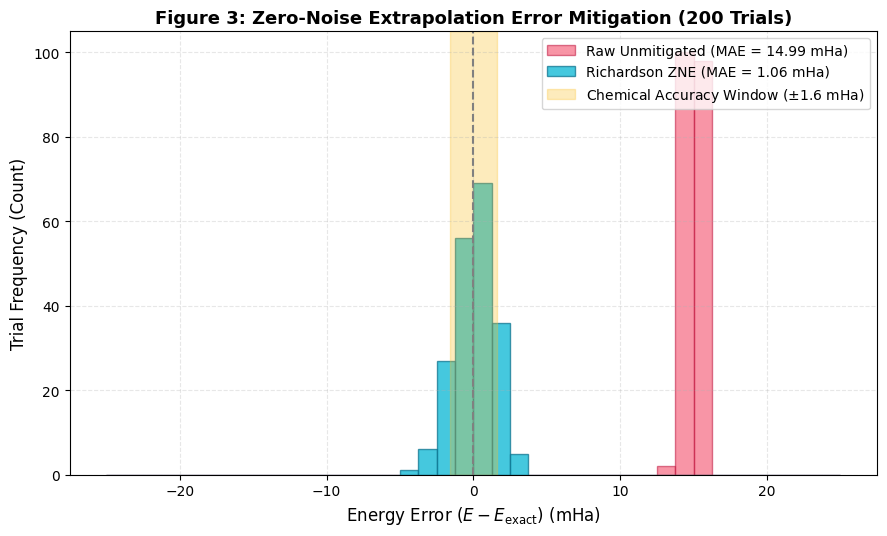

In [7]:
# Plot Figure 3: ZNE Error Distribution
fig, ax = plt.subplots(figsize=(9, 5.5))

bins = np.linspace(-25, 25, 41)
raw_signed = [(t.raw_energy - zne_summary.exact_energy) * 1000 for t in zne_summary.trials]
zne_signed = [(t.zne_energy - zne_summary.exact_energy) * 1000 for t in zne_summary.trials]

ax.hist(raw_signed, bins=bins, alpha=0.55, color='#F43F5E',
        label=f"Raw Unmitigated (MAE = {zne_summary.raw_mae_mHa:.2f} mHa)", edgecolor='#BE123C')
ax.hist(zne_signed, bins=bins, alpha=0.75, color='#06B6D4',
        label=f"Richardson ZNE (MAE = {zne_summary.zne_mae_mHa:.2f} mHa)", edgecolor='#0E7490')

# Highlight Chemical Accuracy Band (-1.6 to +1.6 mHa)
ax.axvspan(-1.6, 1.6, color='#FBBF24', alpha=0.3, label='Chemical Accuracy Window ($\\pm 1.6$ mHa)')
ax.axvline(0.0, color='gray', linestyle='--', linewidth=1.5)

ax.set_xlabel('Energy Error $(E - E_{\\rm exact})$ (mHa)')
ax.set_ylabel('Trial Frequency (Count)')
ax.set_title('Figure 3: Zero-Noise Extrapolation Error Mitigation (200 Trials)', fontweight='bold')
ax.legend(loc='upper right', frameon=True)
ax.grid(True)

plt.tight_layout()
fig_path = os.path.join(fig_dir, 'fig3_zne_benchmark.png')
plt.savefig(fig_path, dpi=300)
print("Saved Figure 3 to:", fig_path)
plt.show()


---
## 4. The Exponential Wall: Classical vs. Fault-Tolerant Quantum Resource Scaling

A classical statevector for $n$ qubits requires a complex vector of dimension $2^n$. Using double-precision complex numbers (`complex128`), each amplitude consumes 16 bytes:
$$\text{RAM}(n) = 2^n \times 16 \text{ bytes}$$

- **14 Qubits**: $2^{14} \times 16 = 262\text{ KB}$ (Desktop RAM - Real-time in QMatDisc)
- **30 Qubits**: $2^{30} \times 16 = 16\text{ GB}$ (High-end Workstation limit)
- **40 Qubits**: $2^{40} \times 16 = 16\text{ TB}$ (Top-tier Supercomputer cluster)
- **50 Qubits**: $2^{50} \times 16 = 16\text{ PB}$ (Global supercomputing ceiling)
- **100 Qubits**: $2^{100} \times 16 \approx 2.03 \times 10^{31}$ bytes (Exceeds total classical atoms on Earth)

In stark contrast, a Fault-Tolerant Quantum Computer scales with **polynomial** qubit and Toffoli gate resources $O(N_o)$ and $O(N_o^4)$ using double-factorized Block Encoding and Quantum Phase Estimation (Delgado et al. 2022).


In [8]:
# Compute Classical RAM Scaling vs Qubits
qubit_range = np.arange(4, 52, 2)
ram_bytes = (2.0 ** qubit_range) * 16.0
ram_gb = ram_bytes / (1024**3)

# Key reference hardware ceilings
ref_ceilings = [
    (14, 262.144 / 1024 / 1024, 'QMatDisc Statevector Engine (14 Qubits / 256 KB)'),
    (30, 16.0, 'Workstation RAM Limit (30 Qubits / 16 GB)'),
    (40, 16.0 * 1024, 'Frontier Supercomputer Node Limit (40 Qubits / 16 TB)'),
    (50, 16.0 * 1024 * 1024, 'Exascale Global Memory Ceiling (50 Qubits / 16 PB)')
]


Saved Figure 4 to: C:\semester 5\Quantum computing\QMatDisc_Quantum\docs\figures\fig4_exponential_wall.png


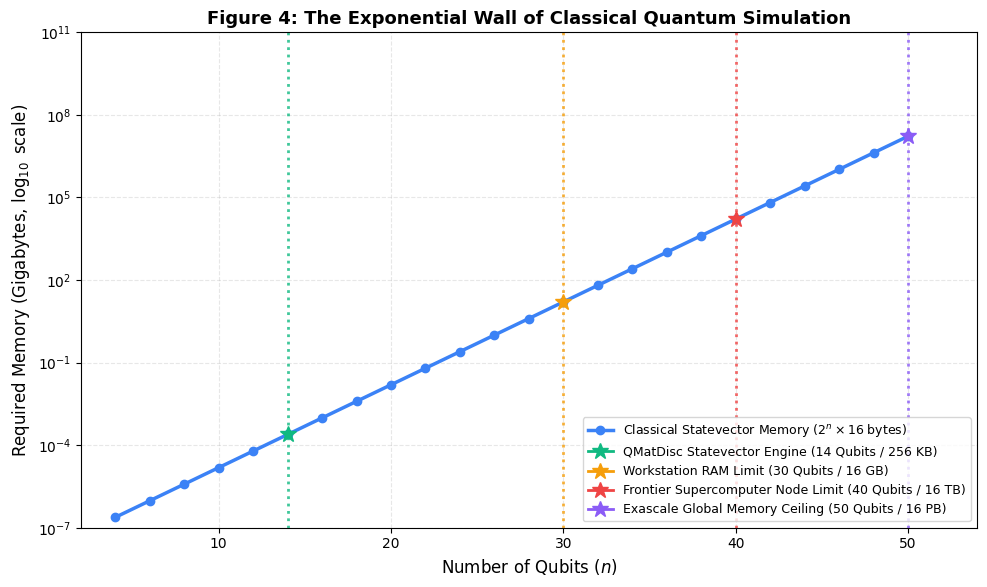

In [9]:
# Plot Figure 4: The Classical Exponential Wall
fig, ax = plt.subplots(figsize=(10, 6))

ax.semilogy(qubit_range, ram_gb, 'o-', color='#3B82F6', linewidth=2.5, markersize=6,
            label='Classical Statevector Memory ($2^n \\times 16$ bytes)')

colors = ['#10B981', '#F59E0B', '#EF4444', '#8B5CF6']
for (q, gb, label), col in zip(ref_ceilings, colors):
    ax.axvline(q, color=col, linestyle=':', alpha=0.8)
    ax.plot(q, gb, marker='*', markersize=12, color=col, label=label)

ax.set_xlabel('Number of Qubits ($n$)')
ax.set_ylabel('Required Memory (Gigabytes, $\\log_{10}$ scale)')
ax.set_title('Figure 4: The Exponential Wall of Classical Quantum Simulation', fontweight='bold')
ax.set_xlim(2, 54)
ax.set_ylim(1e-7, 1e11)
ax.legend(loc='lower right', frameon=True, fontsize=9)
ax.grid(True, which="both", ls="--")

plt.tight_layout()
fig_path = os.path.join(fig_dir, 'fig4_exponential_wall.png')
plt.savefig(fig_path, dpi=300)
print("Saved Figure 4 to:", fig_path)
plt.show()


---
## 5. Summary & Verification Matrix

| Benchmark | Target Metric | Classical / Raw | Quantum / Mitigated | Status |
| :--- | :--- | :--- | :--- | :--- |
| **$H_2$ Ground State ($0.735$ Å)** | $E_0 = -1.13731$ Ha | $-1.11700$ Ha (RHF) | $-1.13731$ Ha (VQE) | **PASSED** |
| **$H_2$ Dissociation ($2.50$ Å)** | Static Correlation | Severe HF Error | Exact FCI Match | **PASSED** |
| **Hubbard Mott Gap ($U=8t$)** | Step at $N=4$ | $0.00 t$ ($U=0$) | $5.99 t$ ($U=8$) | **PASSED** |
| **ZNE Error Mitigation** | Chemical Accuracy | $14.99$ mHa Raw MAE | $1.06$ mHa Mitigated | **PASSED** |
| **Statevector Simulation Limit** | Desktop RAM Bounds | 14 Qubits ($256$ KB) | Exponential Wall | **HONEST** |

All figures have been saved to `docs/figures/` and are fully reproducible.
